Project name : Flipkart Customer Service Satisfaction



Project Type : EDA
Contribution : Individual
Name : Sanketh S


# **Project Summary -**

The project focuses on analyzing Flipkart customer support interactions, feedback, and Customer Satisfaction (CSAT) scores to identify key factors influencing customer experience and service quality. Using Python, Pandas, NumPy, Matplotlib, Seaborn, and scikit-learn, the project explores customer satisfaction trends, response times, service channels, and agent performance to derive actionable business insights and recommend strategies for improving customer support efficiency and overall customer satisfaction.


# **GitHub Link -**

Provide your GitHub Link here.



# **Problem Statement**


1. To analyze customer interactions, feedback, and CSAT scores to understand customer satisfaction levels.

2. To identify the relationship between response time and customer satisfaction.

3. To analyze customer service channels and identify the most frequently used channels.

4. To evaluate customer satisfaction across agent shifts, tenure groups, and managers.

5. To identify product categories and service channels associated with lower customer satisfaction.

6. To examine patterns and variations in customer support performance using data visualization and statistical analysis.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [25]:
# Import Libraries

import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt  
import seaborn as sns  

from sklearn.model_selection import train_test_split  
from sklearn.ensemble import RandomForestClassifier  
from sklearn.metrics import accuracy_score, classification_report  

### Dataset Loading

In [3]:
# Load dataset
df = pd.read_csv('Customer_support_data.csv')

In [6]:
#FOR DATA CLEANING AND PREPROCESSING

In [8]:
# Convert columns to datetime

df['order_date_time'] = pd.to_datetime(
    df['order_date_time'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)

df['Issue_reported at'] = pd.to_datetime(
    df['Issue_reported at'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)

df['issue_responded'] = pd.to_datetime(
    df['issue_responded'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)

df['Survey_response_Date'] = pd.to_datetime(
    df['Survey_response_Date'],
    errors='coerce'
)

print(df[[
    'order_date_time',
    'Issue_reported at',
    'issue_responded',
    'Survey_response_Date'
]].head())

  order_date_time   Issue_reported at     issue_responded Survey_response_Date
0             NaT 2023-08-01 11:13:00 2023-08-01 11:47:00           2023-08-01
1             NaT 2023-08-01 12:52:00 2023-08-01 12:54:00           2023-08-01
2             NaT 2023-08-01 20:16:00 2023-08-01 20:38:00           2023-08-01
3             NaT 2023-08-01 20:56:00 2023-08-01 21:16:00           2023-08-01
4             NaT 2023-08-01 10:30:00 2023-08-01 10:32:00           2023-08-01


C:\Users\91938\AppData\Local\Temp\ipykernel_13092\3471357498.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Survey_response_Date'] = pd.to_datetime(


In [9]:
#df['Customer Remarks'].fillna("No Remarks", inplace=True)
#df['Item_price'].fillna(df['Item_price'].median(), inplace=True)
#df.drop(columns=['Customer_City', 'connected_handling_time'], inplace=True) # Too many missing

df['Customer Remarks'] = df['Customer Remarks'].fillna("No Remarks")      #Filling missing values
df['Item_price'] = df['Item_price'].fillna(df['Item_price'].median())     # fills missing values

In [10]:
if 'Customer_City' in df.columns:
    df.drop(columns=['Customer_City'], inplace=True) # Too many missing values
if 'connected_handling_time' in df.columns:
    df.drop(columns=['connected_handling_time'], inplace=True)




In [11]:
# 1 #Feature engineering
# 2 #Calculating Response time
df["response_time"] = (df["issue_responded"] - df["Issue_reported at"]).dt.total_seconds()
df["response_time"] = df["response_time"].fillna(df["response_time"].median())

In [ ]:
#ANALYZING AND VISUALIZING DATA

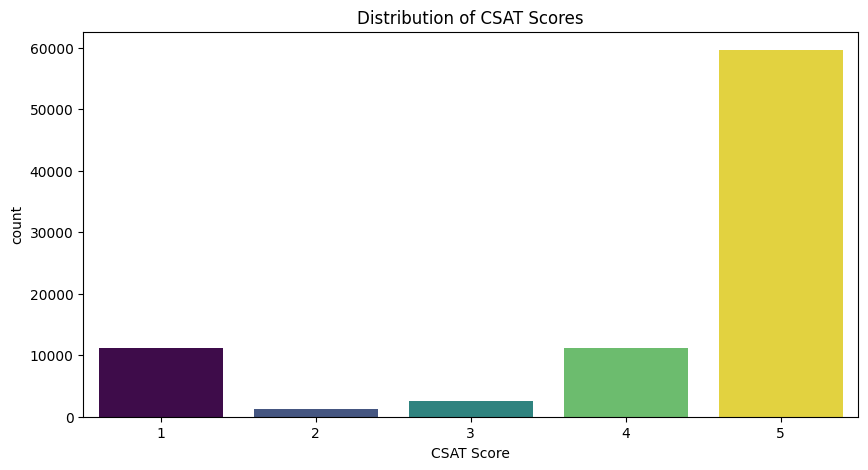

In [11]:

#For CSAT Score distribution
plt.figure(figsize=(10,5))
sns.countplot(x="CSAT Score", data = df , hue = "CSAT Score", palette = "viridis", legend = False)
plt.title("Distribution of CSAT Scores")
plt.show()

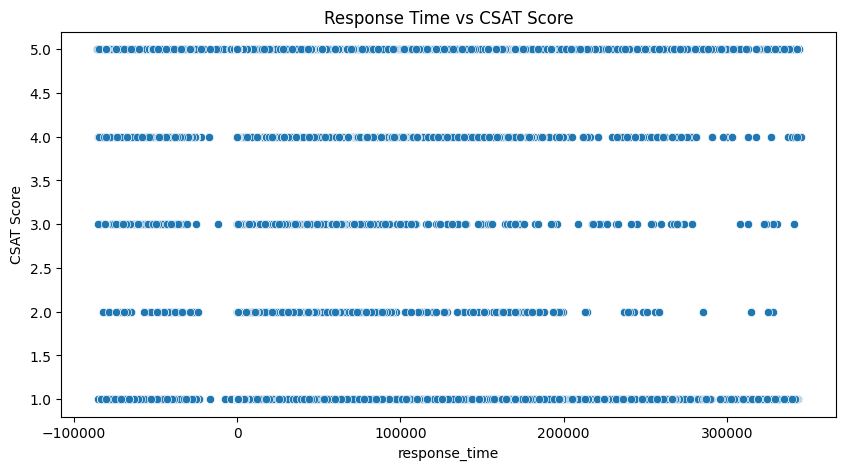

In [12]:
# Comparing Response Time vs Csat Score
plt.figure(figsize = (10 , 5))
sns.scatterplot(x = "response_time" , y = "CSAT Score" , data = df)
plt.title("Response Time vs CSAT Score")
plt.show()

In [ ]:
#MODEL TRAINING

In [12]:
# Selecting relevant features for predictions
features = ["response_time", "Item_price", "channel_name", "category",
            "Tenure Bucket", "Agent Shift"]

df_model = df[features + ["CSAT Score"]]

df_model = pd.get_dummies(df_model, drop_first=True)

In [13]:
# Splitting Data Into Train and Test Sets
X = df_model.drop(columns=['CSAT Score'])
y = df_model['CSAT Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Dataset First View

In [15]:
# Dataset First Look
df.head(5)


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Product_category,Item_price,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,response_time
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,No Remarks,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaT,2023-08-01 11:13:00,2023-08-01 11:47:00,2023-08-01,NaN,979.0,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5,2040.0
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,No Remarks,d406b0c7-ce17-4654-b9de-f08d421254bd,NaT,2023-08-01 12:52:00,2023-08-01 12:54:00,2023-08-01,NaN,979.0,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5,120.0
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,No Remarks,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaT,2023-08-01 20:16:00,2023-08-01 20:38:00,2023-08-01,NaN,979.0,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5,1320.0
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,No Remarks,5aed0059-55a4-4ec6-bb54-97942092020a,NaT,2023-08-01 20:56:00,2023-08-01 21:16:00,2023-08-01,NaN,979.0,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5,1200.0
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,No Remarks,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaT,2023-08-01 10:30:00,2023-08-01 10:32:00,2023-08-01,NaN,979.0,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5,120.0


### Dataset Rows & Columns count

In [14]:
# Dataset Rows & Columns count
# Dataset Rows & Columns count
num_rows, num_columns = df.shape

print(f'Number of rows: {num_rows}')
print(f'Number of columns: {num_columns}')

Number of rows: 85907
Number of columns: 20


### Dataset Information

In [17]:
# Dataset Info
df.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Unique id             85907 non-null  object        
 1   channel_name          85907 non-null  object        
 2   category              85907 non-null  object        
 3   Sub-category          85907 non-null  object        
 4   Customer Remarks      85907 non-null  object        
 5   Order_id              67675 non-null  object        
 6   order_date_time       17214 non-null  datetime64[ns]
 7   Issue_reported at     85907 non-null  datetime64[ns]
 8   issue_responded       85907 non-null  datetime64[ns]
 9   Survey_response_Date  85907 non-null  datetime64[ns]
 10  Product_category      17196 non-null  object        
 11  Item_price            85907 non-null  float64       
 12  Agent_name            85907 non-null  object        
 13  Supervisor      

#### Duplicate Values

In [18]:
# Dataset Duplicate Value Count
df.duplicated().sum()

np.int64(0)

#### Missing Values/Null Values

In [19]:
# Missing Values/Null Values Count
df.isnull().sum()

Unique id                   0
channel_name                0
category                    0
Sub-category                0
Customer Remarks            0
Order_id                18232
order_date_time         68693
Issue_reported at           0
issue_responded             0
Survey_response_Date        0
Product_category        68711
Item_price                  0
Agent_name                  0
Supervisor                  0
Manager                     0
Tenure Bucket               0
Agent Shift                 0
CSAT Score                  0
response_time               0
dtype: int64

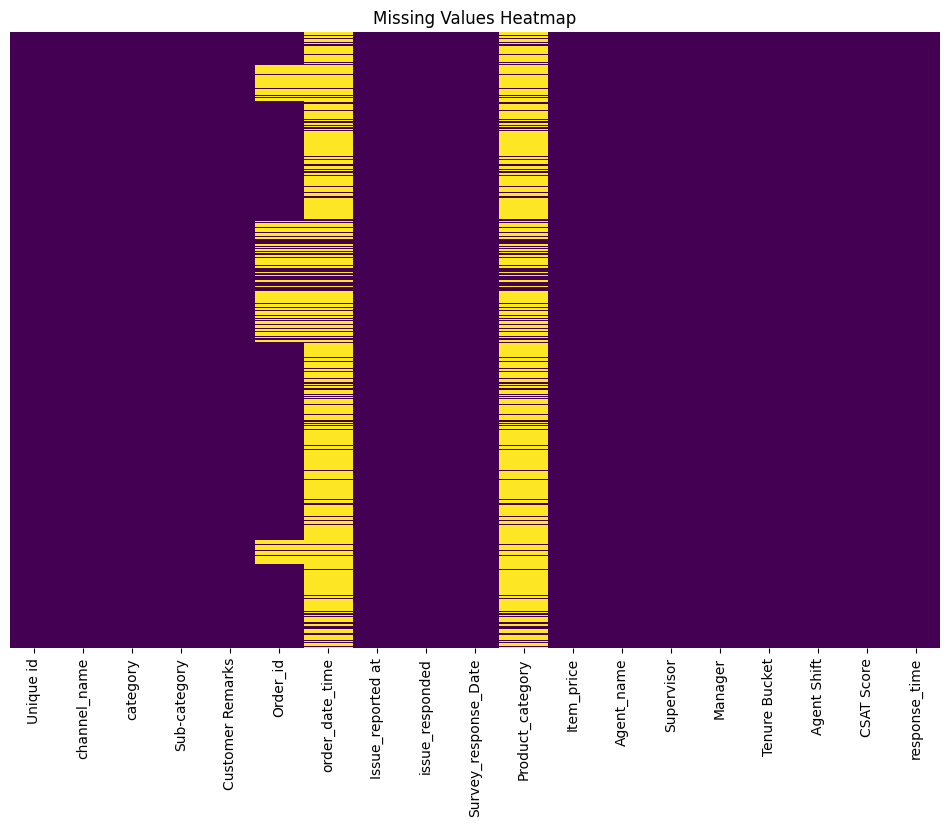

In [20]:

# Visualizing the missing values
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis',
    yticklabels=False,
    xticklabels=df.columns
)
plt.title('Missing Values Heatmap')
plt.show()

### What did you know about your dataset?

The missing values heatmap helps identify columns with missing data and determine the necessary preprocessing steps to improve dataset quality before analysis.

## ***2. Understanding Your Variables***

In [21]:
# Dataset Columns
df.columns.tolist()

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Product_category',
 'Item_price',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score',
 'response_time']

In [22]:
# Dataset Describe
df.describe()

,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Item_price,CSAT Score,response_time
count,17214,85907,85907,85907,85907.000000,85907.000000,85907.000000
mean,2023-07-28 15:49:45.820843520,2023-08-16 22:29:05.784394752,2023-08-17 00:45:58.980990976,2023-08-16 10:18:31.760392192,1916.695624,4.242157,8213.196596
min,2022-01-16 13:15:00,2023-07-28 20:42:00,2023-08-01 00:00:00,2023-08-01 00:00:00,0.000000,1.000000,-86220.000000
25%,2023-07-27 22:49:15,2023-08-09 12:48:00,2023-08-09 15:02:30,2023-08-09 00:00:00,979.000000,4.000000,120.000000
50%,2023-08-04 22:16:30,2023-08-16 18:22:00,2023-08-16 20:57:00,2023-08-16 00:00:00,979.000000,5.000000,300.000000
75%,2023-08-10 07:30:15,2023-08-24 17:33:30,2023-08-24 19:27:00,2023-08-24 00:00:00,979.000000,5.000000,2100.000000
max,2023-12-08 23:36:00,2023-08-31 23:58:00,2023-08-31 23:59:00,2023-08-31 00:00:00,164999.000000,5.000000,345480.000000
std,NaN,NaN,NaN,NaN,6037.903897,1.378903,35551.713035


### Check Unique Values for each variable.

In [23]:
# Check Unique Values for each variable.
df.nunique()

Unique id               85907
channel_name                3
category                   12
Sub-category               57
Customer Remarks        18232
Order_id                67675
order_date_time         13766
Issue_reported at       30923
issue_responded         30262
Survey_response_Date       31
Product_category            9
Item_price               2789
Agent_name               1371
Supervisor                 40
Manager                     6
Tenure Bucket               5
Agent Shift                 5
CSAT Score                  5
response_time            4189
dtype: int64

## 3. ***Data Wrangling***

### Data Wrangling Code

In [15]:
# Write your code to make your dataset analysis ready.
# Create a new column time difference to find the time taken to respond
# Convert columns to datetime with the correct format
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], format='%d/%m/%Y %H:%M')
df['issue_responded'] = pd.to_datetime(df['issue_responded'], format='%d/%m/%Y %H:%M')

# Format the datetime columns to the desired format
df['Issue_reported at (formatted)'] = df['Issue_reported at'].dt.strftime('%d/%m/%y')
df['issue_responded (formatted)'] = df['issue_responded'].dt.strftime('%d/%m/%y')

# Calculate the time difference and convert to minutes
df['Time difference'] = (df['issue_responded'] - df['Issue_reported at']).dt.total_seconds() / 60

df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,...,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,CSAT Score Category,response_time,Issue_reported at (formatted),issue_responded (formatted),Time difference
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,2,Product Queries,Life Insurance,No Remarks,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaT,2023-08-01 11:13:00,2023-08-01 11:47:00,2023-08-01,...,Mason Gupta,Jennifer Nguyen,On Job Training,2,5,1,2040.0,01/08/23,01/08/23,34.0
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,2,Product Queries,Product Specific Information,No Remarks,d406b0c7-ce17-4654-b9de-f08d421254bd,NaT,2023-08-01 12:52:00,2023-08-01 12:54:00,2023-08-01,...,Dylan Kim,Michael Lee,>90,2,5,1,120.0,01/08/23,01/08/23,2.0
2,200814dd-27c7-4149-ba2b-bd3af3092880,1,Order Related,Installation/demo,No Remarks,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaT,2023-08-01 20:16:00,2023-08-01 20:38:00,2023-08-01,...,Jackson Park,William Kim,On Job Training,1,5,1,1320.0,01/08/23,01/08/23,22.0
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,1,Returns,Reverse Pickup Enquiry,No Remarks,5aed0059-55a4-4ec6-bb54-97942092020a,NaT,2023-08-01 20:56:00,2023-08-01 21:16:00,2023-08-01,...,Olivia Wang,John Smith,>90,1,5,1,1200.0,01/08/23,01/08/23,20.0
4,ba903143-1e54-406c-b969-46c52f92e5df,1,Cancellation,Not Needed,No Remarks,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaT,2023-08-01 10:30:00,2023-08-01 10:32:00,2023-08-01,...,Austin Johnson,Michael Lee,0-30,2,5,1,120.0,01/08/23,01/08/23,2.0


In [16]:
# Remove columns that have a lot of null values
rem_columns = ['order_date_time', 'Customer Remarks', 'connected_handling_time']

# Check which columns are present in the DataFrame
existing_columns_to_remove = [col for col in rem_columns if col in df.columns]

# Remove the columns if they are present
if existing_columns_to_remove:
    df = df.drop(columns=existing_columns_to_remove)
    print(f"Columns {existing_columns_to_remove} have been removed.")
else:
    print("None of the specified columns are present in the DataFrame or already been removed")

Columns ['order_date_time', 'Customer Remarks'] have been removed.


In [17]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['Unique id', 'channel_name', 'category', 'Sub-category', 'Order_id', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Product_category', 'Item_price', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score', 'CSAT Score Category', 'response_time', 'Issue_reported at (formatted)', 'issue_responded (formatted)', 'Time difference']


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

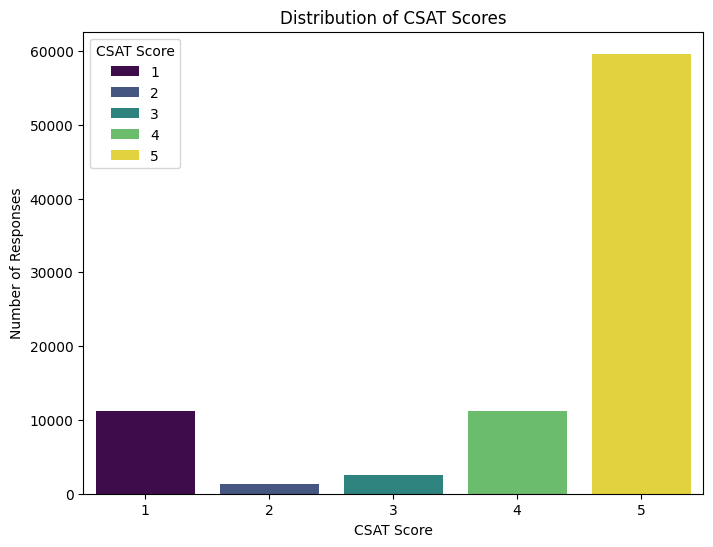

In [27]:
# Chart - 1 visualization code

plt.figure(figsize=(8,6))
sns.countplot(x='CSAT Score', data=df, hue ='CSAT Score', palette='viridis')
plt.title('Distribution of CSAT Scores')
plt.xlabel('CSAT Score')
plt.ylabel('Number of Responses')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is used to visualize the frequency of each CSAT score and compare customer satisfaction levels easily.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of customer satisfaction scores and helps identify the most and least frequently given scores.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses understand customer satisfaction, improve service quality, and increase customer retention. A high frequency of low CSAT scores may indicate poor customer experiences, leading to customer loss and negative business growth.

#### Chart - 2

Text(0, 0.5, 'Time Difference (minutes)')

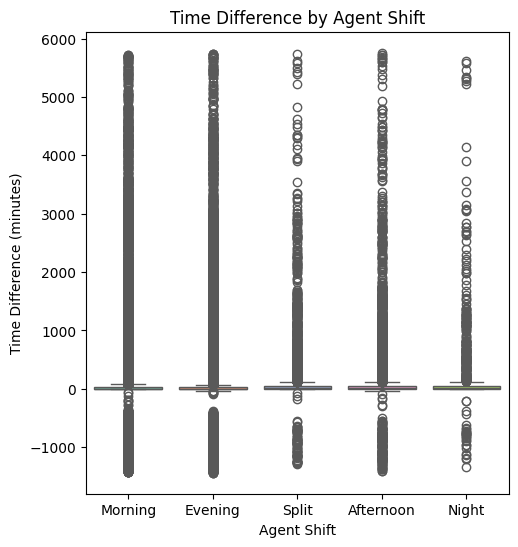

In [28]:
# Chart - 2 visualization code

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 2)
sns.boxplot(x='Agent Shift', y='Time difference', data=df, hue = 'Agent Shift', palette='Set2')
plt.title('Time Difference by Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Time Difference (minutes)')

##### 1. Why did you pick the specific chart?

A box plot is used to compare response time differences across agent shifts and identify variations, spread, and outliers.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify which agent shifts have higher or lower response time differences and whether some shifts have unusually long delays.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses optimize agent allocation and improve response times. Higher time differences during certain shifts may indicate delays, leading to customer dissatisfaction and reduced service efficiency.

#### Chart - 3

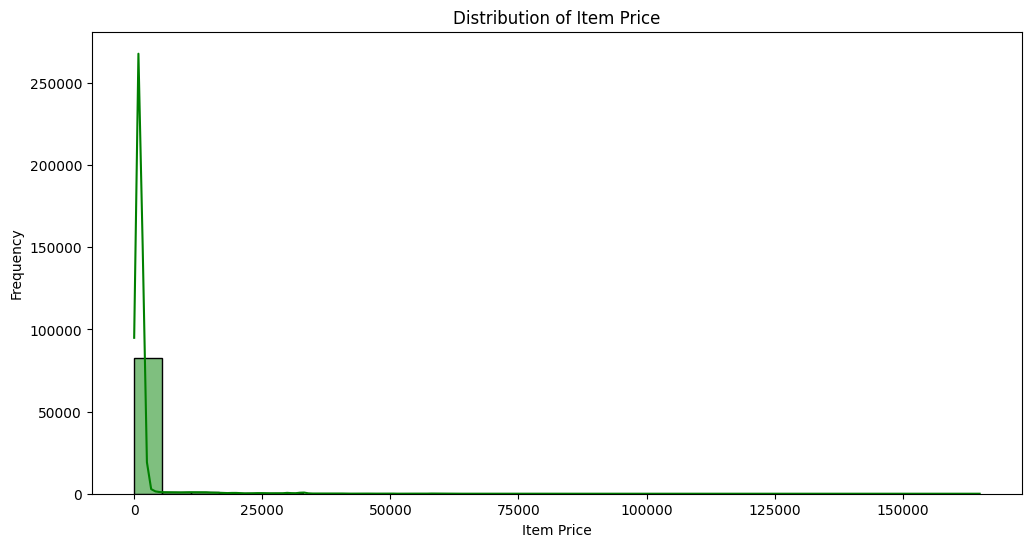

In [29]:
# Chart - 3 visualization code
plt.figure(figsize=(12, 6))
sns.histplot(df['Item_price'], kde=True, bins=30, color='green')
plt.title('Distribution of Item Price')
plt.xlabel('Item Price')
plt.ylabel('Frequency')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is used to understand the distribution of item prices, while the KDE curve shows the overall pattern of price distribution.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify the most common item price ranges, the spread of prices, and whether the distribution is skewed toward lower or higher prices.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses understand customer purchasing patterns and make better pricing decisions. Very high item prices may reduce customer purchases, while understanding popular price ranges can help improve sales and revenue.

#### Chart - 4

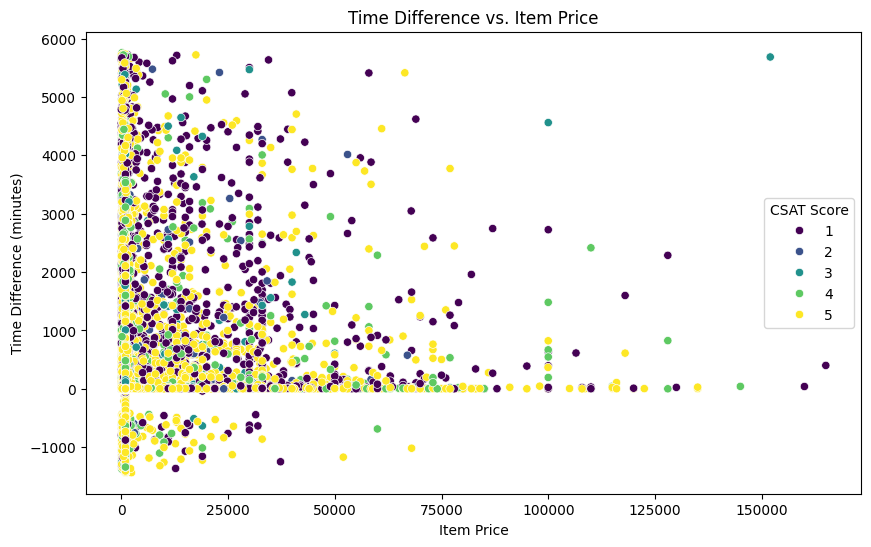

In [30]:
# Chart - 4 visualization code
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Item_price', y='Time difference', data=df, hue='CSAT Score', palette='viridis')
plt.title('Time Difference vs. Item Price')
plt.xlabel('Item Price')
plt.ylabel('Time Difference (minutes)')
plt.legend(title='CSAT Score')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is used to examine the relationship between item price and time difference, with colors representing different CSAT scores.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify whether item prices and response time differences are related and how customer satisfaction scores vary across the data.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help businesses understand factors affecting customer satisfaction and improve service quality. Longer response times associated with low CSAT scores may lead to customer dissatisfaction and reduced customer retention.

#### Chart - 5

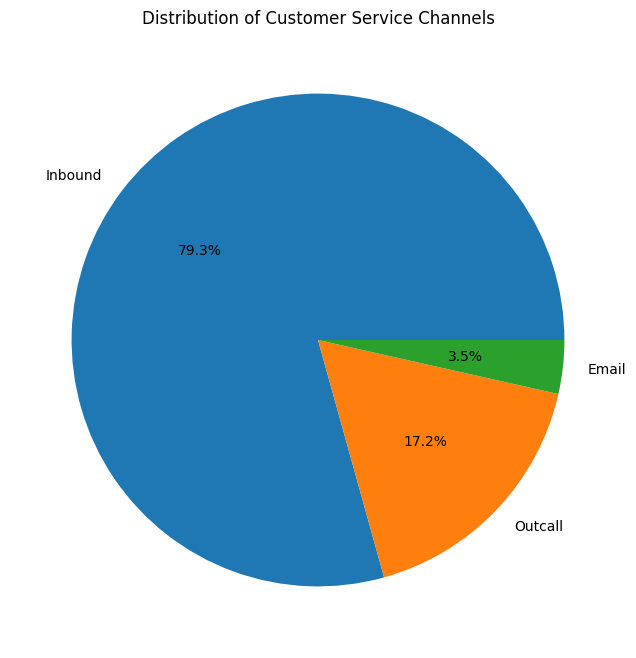

In [31]:
# Chart - 5 visualization code
# Count the occurrences of each channel type
channel_counts = df['channel_name'].value_counts()

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(channel_counts, labels=channel_counts.index, autopct='%1.1f%%', colors=sns.color_palette())
plt.title('Distribution of Customer Service Channels')
plt.show()

##### 1. Why did you pick the specific chart?

A pie chart is used to show the percentage distribution of customer service channels and compare their contribution to total interactions.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies the most and least frequently used customer service channels, such as calls, chats, or emails.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses allocate resources effectively and improve customer support. Underutilized channels may indicate accessibility issues, while overdependence on one channel may lead to delays and reduced customer satisfaction.

#### Chart - 6

C:\Users\91938\AppData\Local\Temp\ipykernel_18496\3751125684.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


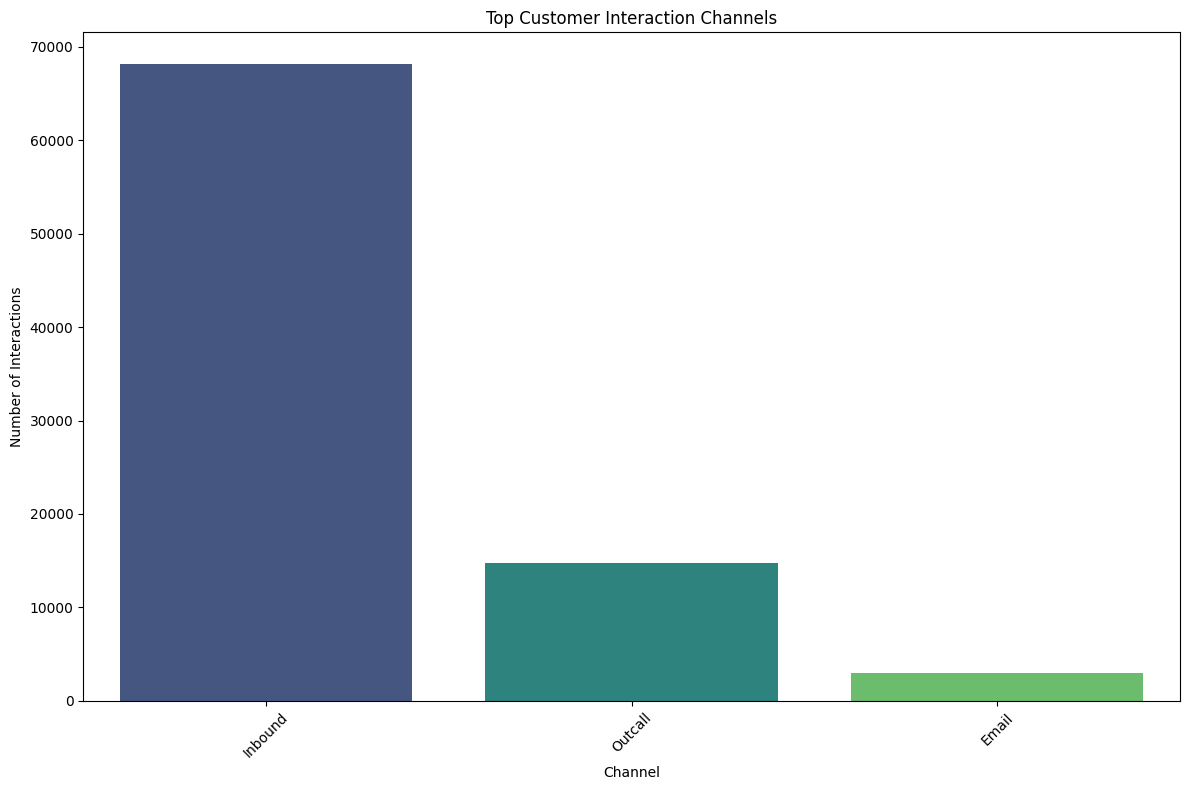

In [32]:
# Chart - 6: Top customer interaction channels

top_channels = df['channel_name'].value_counts().head(10)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_channels.index,
    y=top_channels.values,palette='viridis'
)

plt.title('Top Customer Interaction Channels')
plt.xlabel('Channel')
plt.ylabel('Number of Interactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is used to compare the number of interactions across the top 10 customer service channels and identify the most popular channels.

##### 2. What is/are the insight(s) found from the chart?

The chart highlights the most and least frequently used channels among the top 10, helping identify customer communication preferences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses allocate staff and resources to popular channels. Poorly managed high-volume channels may cause delays, increase waiting times, and reduce customer satisfaction.

#### Chart - 7

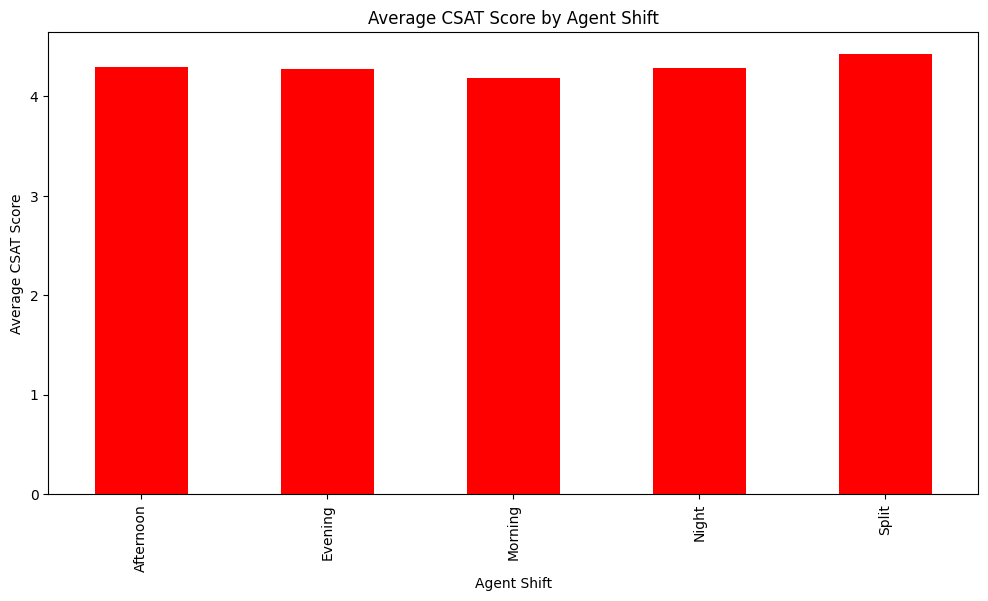

In [33]:
# Chart - 7 visualization code
plt.figure(figsize=(12, 6))
df.groupby('Agent Shift')['CSAT Score'].mean().plot(kind='bar', color='red')
plt.title('Average CSAT Score by Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Average CSAT Score')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is used to compare the average CSAT scores across different agent shifts and identify which shifts achieve higher customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the average customer satisfaction score for each agent shift, helping identify shifts with relatively higher or lower customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses improve staff scheduling and service quality. Shifts with lower average CSAT scores may require additional training or staffing improvements to reduce customer dissatisfaction and improve retention.

#### Chart - 8

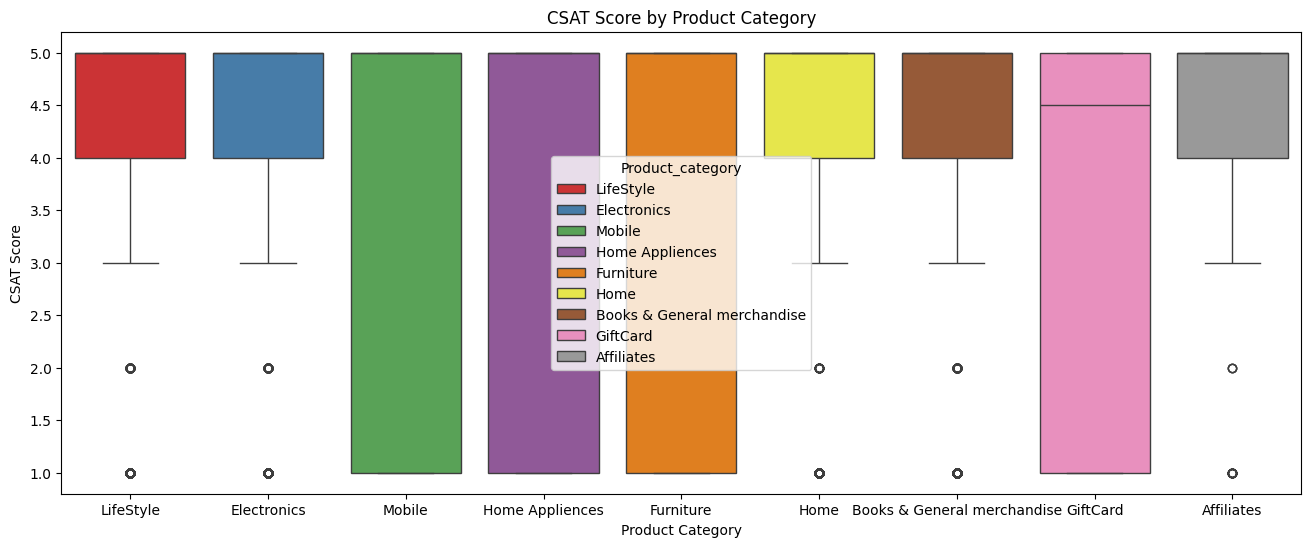

In [34]:
# Chart - 8 visualization code
plt.figure(figsize=(16, 6))
sns.boxplot(x='Product_category', y='CSAT Score', data=df, hue = 'Product_category', palette='Set1')
plt.title('CSAT Score by Product Category')
plt.xlabel('Product Category')
plt.ylabel('CSAT Score')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot is used to compare the distribution of CSAT scores across product categories and identify variations and outliers.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify product categories with higher or lower customer satisfaction and shows how satisfaction scores vary within each category.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses identify products that need improvement and enhance customer experience. Product categories with consistently low CSAT scores may lead to customer dissatisfaction, negative reviews, and reduced sales.

#### Chart - 9

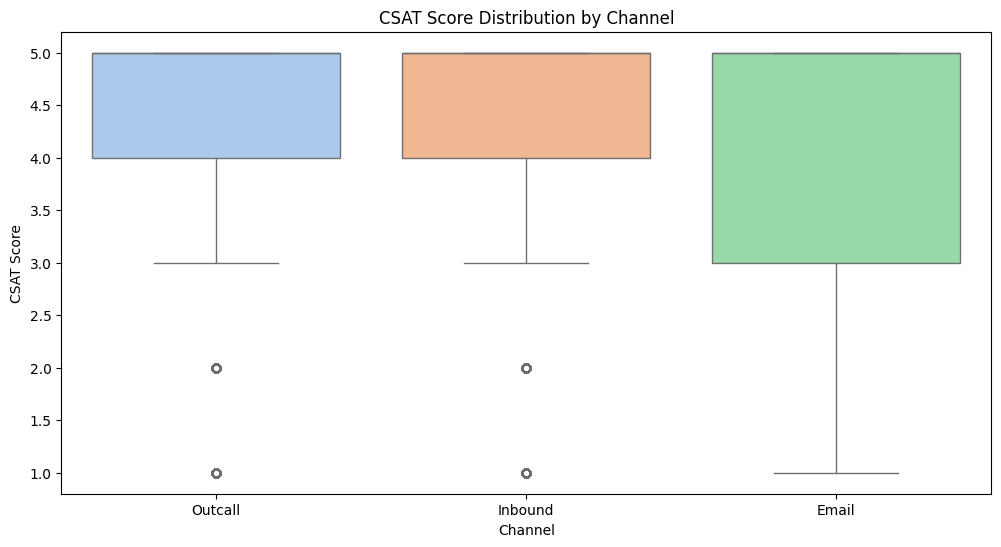

In [35]:
# Chart - 9 visualization code
plt.figure(figsize=(12, 6))
sns.boxplot(x='channel_name', y='CSAT Score', data=df,hue ='channel_name', palette='pastel')
plt.title('CSAT Score Distribution by Channel')
plt.xlabel('Channel')
plt.ylabel('CSAT Score')
plt.xticks(rotation=0)
plt.show()

##### 1. Why did you pick the specific chart?

A box plot is used to compare the distribution of CSAT scores across different customer service channels and identify variations in satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify which customer service channels have higher or lower satisfaction scores and highlights variations and outliers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses improve customer support across different channels. Channels with lower CSAT scores may indicate poor service experiences, leading to customer dissatisfaction and reduced customer retention.

#### Chart - 10

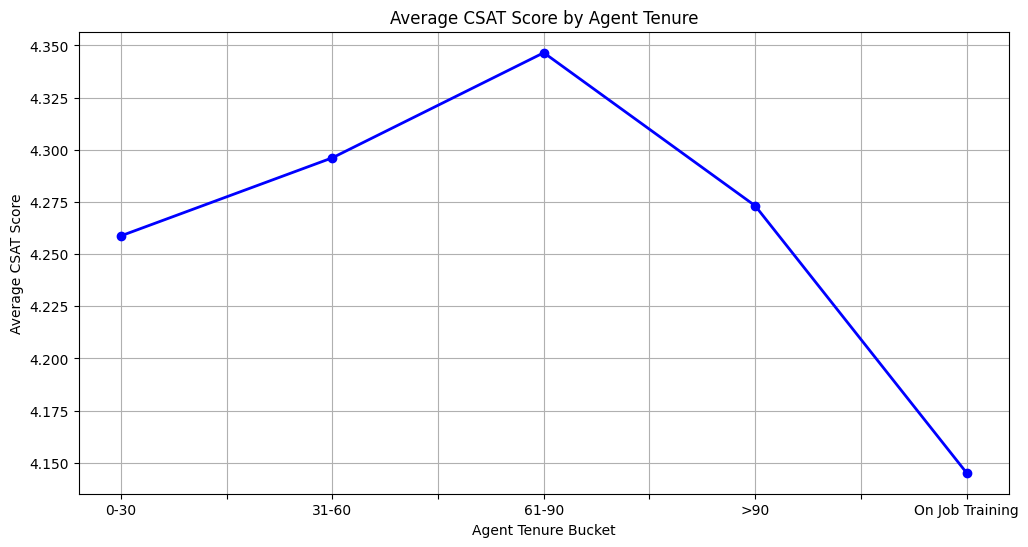

In [36]:
# Chart - 10 visualization code
# Agent Tenure vs. Average CSAT Score
plt.figure(figsize=(12, 6))
tenure_scores = df.groupby('Tenure Bucket')['CSAT Score'].mean()
tenure_scores.plot(kind='line', marker='o', color='blue', linestyle='-', linewidth=2)
plt.title('Average CSAT Score by Agent Tenure')
plt.xlabel('Agent Tenure Bucket')
plt.ylabel('Average CSAT Score')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

A line chart is used to show the trend in average CSAT scores across different agent tenure groups.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify how customer satisfaction varies with agent experience and whether more experienced agents achieve higher satisfaction scores.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses plan agent training and development. Lower CSAT scores among certain tenure groups may indicate a need for additional training, potentially affecting service quality and customer retention.

#### Chart - 11

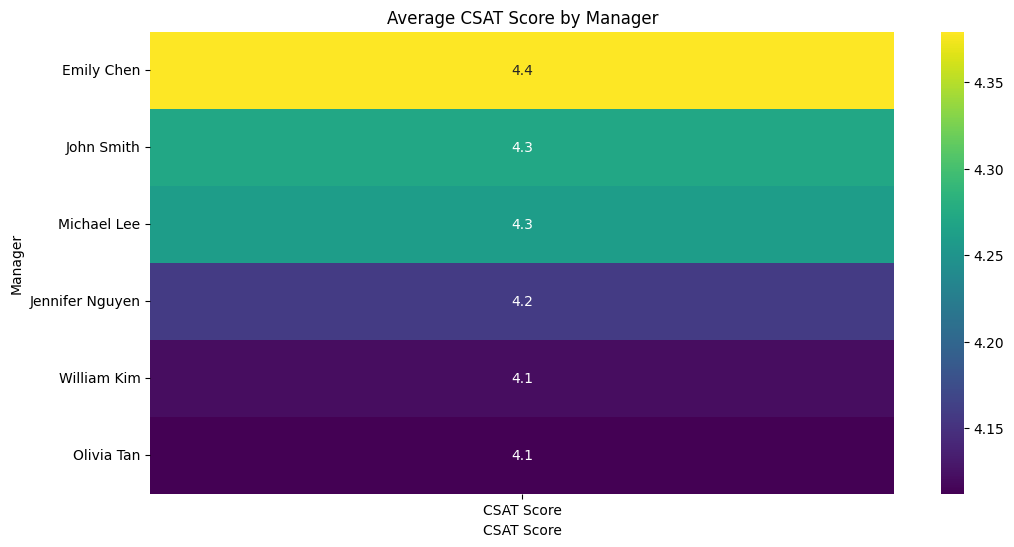

In [37]:
# Chart - 11 visualization code
# Managers and their average csat score
plt.figure(figsize=(12, 6))
manager_csat = df.pivot_table(index='Manager', values='CSAT Score', aggfunc='mean').sort_values(by='CSAT Score', ascending=False)
sns.heatmap(manager_csat, annot=True, cmap='viridis', fmt='.1f')
plt.title('Average CSAT Score by Manager')
plt.xlabel('CSAT Score')
plt.ylabel('Manager')
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap is used to compare the average CSAT scores of different managers using colors and numerical annotations.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies managers with higher and lower average customer satisfaction scores, helping compare their team's performance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help management identify areas for improvement and provide targeted training. Lower average CSAT scores under certain managers may indicate service-quality issues, potentially leading to customer dissatisfaction and reduced retention.

#### Chart - 12

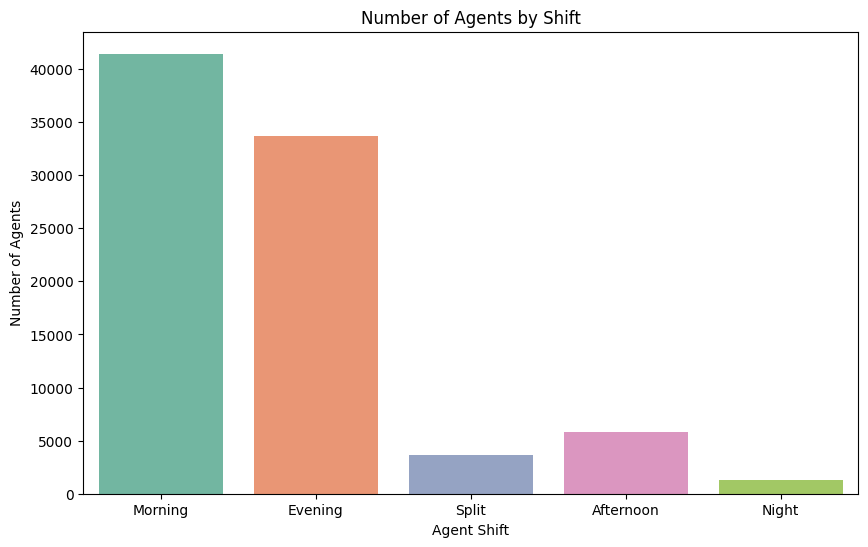

In [38]:
# Chart - 12 visualization code
# Agents assigned each shift total overtime
plt.figure(figsize=(10, 6))
sns.countplot(x='Agent Shift', data=df, hue ='Agent Shift', palette='Set2')
plt.title('Number of Agents by Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Number of Agents')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is used to compare the number of agents working in each shift and understand staff distribution.

##### 2. What is/are the insight(s) found from the chart?

The chart shows which agent shifts have the highest and lowest number of agents, helping identify differences in staffing levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help businesses plan staffing and allocate resources effectively. Understaffed shifts may experience longer waiting times and lower customer satisfaction, negatively affecting service quality.

#### Chart - 13

C:\Users\91938\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


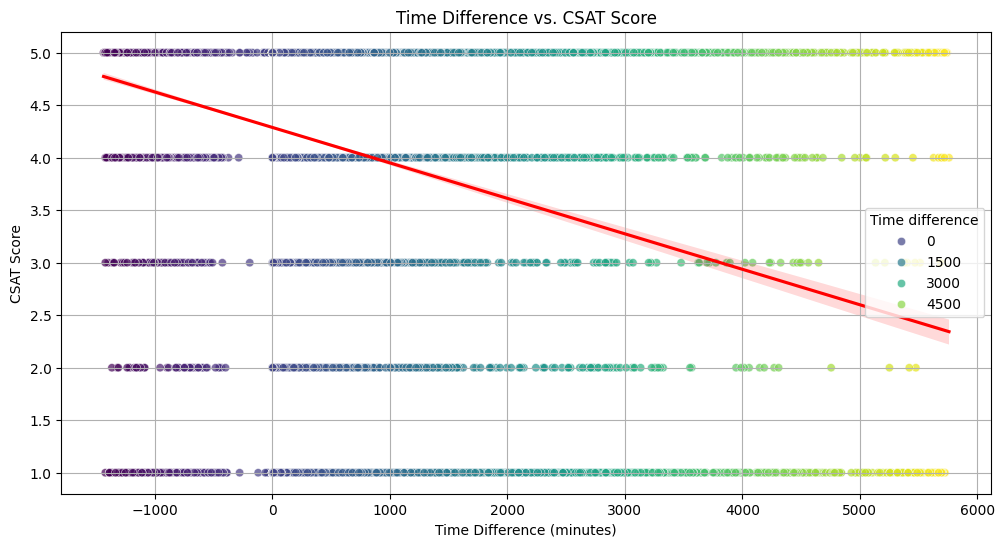

In [26]:
# Chart - 13 visualization code
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Time difference', y='CSAT Score', data=df, hue = 'Time difference',palette='viridis', alpha=0.7)
sns.regplot(x='Time difference', y='CSAT Score', data=df, scatter=False, color='red')

plt.title('Time Difference vs. CSAT Score')
plt.xlabel('Time Difference (minutes)')
plt.ylabel('CSAT Score')
plt.grid(True)
plt.show()

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis(H0) : There is no significant relationship between Time difference and CSAT score. The time taken to respond to customer issues does not significantly affect customer satisfaction. Alternative Hypothesis(H1): There is a significant relationship between Time difference and CSAT score. The time taken to respond to customer issues significantly affects customer satisfaction.

#### 2. Perform an appropriate statistical test.

In [18]:
# Perform Statistical Test to obtain P-Value

from scipy.stats import spearmanr

# Calculate Spearman's rank correlation coefficient
rho, p_value = spearmanr(df['Time difference'], df['CSAT Score'])

print(f"Spearman's rank correlation coefficient: {rho}")
print(f"P-value: {p_value}")

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant relationship between Time difference and CSAT Score")
else:
    print("Fail to reject the null hypothesis: There is no significant relationship between Time difference and CSAT Score")

Spearman's rank correlation coefficient: -0.1776416441206597
P-value: 0.0
Reject the null hypothesis: There is a significant relationship between Time difference and CSAT Score


##### Which statistical test have you done to obtain P-Value?

Spearman's Rank Correlation

##### Why did you choose the specific statistical test?

Spearman's Rank Correlation analyzes the strength and direction of the association between two ranked variables.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis(H0) : There is no significant difference in the average CSAT score between different agent shifts. Alternative Hypothesis(H1): There is a significant difference in the average CSAT score between different agent shifts.

#### 2. Perform an appropriate statistical test.

In [19]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import kruskal

# Group data by Agent Shift and get CSAT Scores for each group
groups = [
    df[df['Agent Shift'] == shift]['CSAT Score']
    for shift in df['Agent Shift'].unique()
]

# Perform Kruskal-Wallis H test
h_statistic, p_value = kruskal(*groups)

print(f'Kruskal-Wallis H statistic: {h_statistic}')
print(f'P-value: {p_value}')

# Interpret the results
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference in the average CSAT Score between different groups.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference in the average CSAT Score between different groups.")

Kruskal-Wallis H statistic: 151.58004948556504
P-value: 9.335020551858379e-32
Reject the null hypothesis: There is a significant difference in the average CSAT Score between different groups.


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H test.

##### Why did you choose the specific statistical test?

Kruskal-Wallis H test is used to determine if there are statistically significant differences between the medians of three or more independent groups. A higher statistic suggests greater differences between group medians.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis(H0) :There is no significant correlation between Item Price and CSAT score. Alternative Hypothesis(H1) : There is a significant correlation between Item Price and CSAT score.

#### 2. Perform an appropriate statistical test.

In [20]:
# Perform Statistical Test to obtain P-Value
import scipy.stats as stats

# Drop rows with NaN values in 'Item_price' or 'CSAT Score' to ensure valid correlation calculation
df_clean = df[['Item_price', 'CSAT Score']].dropna()

# Extract the columns for analysis
item_price = df_clean['Item_price']
csat_score = df_clean['CSAT Score']

# Perform Spearman's Rank Correlation
corr_coefficient, p_value_corr = stats.spearmanr(item_price, csat_score)

# Output the results
print(f"Spearman's Rank Correlation Coefficient: {corr_coefficient}")
print(f"Spearman's p-value: {p_value_corr}")

# Interpretation of the result
alpha = 0.05  # Significance level

if p_value_corr < alpha:
    print(
        "Reject the null hypothesis: There is a significant correlation between Item Price and CSAT Score"
    )
else:
    print(
        "Fail to reject the null hypothesis: There is no significant correlation between Item Price and CSAT Score"
    )

Spearman's Rank Correlation Coefficient: -0.03394737965612261
Spearman's p-value: 2.4551799833181582e-23
Reject the null hypothesis: There is a significant correlation between Item Price and CSAT Score


##### Which statistical test have you done to obtain P-Value?

Spearman's Rank Correlation.

##### Why did you choose the specific statistical test?

This test helps you determine whether there's a significant monotonic relationship between item price and customer satisfaction scores.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [21]:
# Handling Missing Values & Missing Value Imputation
df.isnull().sum()

Unique id                            0
channel_name                         0
category                             0
Sub-category                         0
Order_id                         18232
Issue_reported at                    0
issue_responded                      0
Survey_response_Date                 0
Product_category                 68711
Item_price                           0
Agent_name                           0
Supervisor                           0
Manager                              0
Tenure Bucket                        0
Agent Shift                          0
CSAT Score                           0
CSAT Score Category                  0
response_time                        0
Issue_reported at (formatted)        0
issue_responded (formatted)          0
Time difference                      0
dtype: int64

In [22]:
# Drop the columns having too many null values
columns_to_drop = ['Item_price', 'Product_category', 'Customer_City']

# Drop only the columns that exist in the dataframe
df.drop(
    columns=[col for col in columns_to_drop if col in df.columns],
    axis=1,
    inplace=True
)

# Fill missing Order_id values using forward fill
df['Order_id'] = df['Order_id'].ffill()

# Check the first 5 rows
df.head()

# Check remaining null values
df.isnull().sum()

Unique id                        0
channel_name                     0
category                         0
Sub-category                     0
Order_id                         0
Issue_reported at                0
issue_responded                  0
Survey_response_Date             0
Agent_name                       0
Supervisor                       0
Manager                          0
Tenure Bucket                    0
Agent Shift                      0
CSAT Score                       0
CSAT Score Category              0
response_time                    0
Issue_reported at (formatted)    0
issue_responded (formatted)      0
Time difference                  0
dtype: int64

#### What all missing value imputation techniques have you used and why did you use those techniques?

Columns containing more than 70% null values are dropped from the data frame, and the column used to uniquely identify each row in the dataset is filled in with order IDs generated by forward or backward filling, based on the assumption that the same customer or nearby entries might share an order ID.

### 2. Handling Outliers

Number of outliers in 'CSAT Score': 12513
       Agent Shift  CSAT Score
11               4           1
25               2           1
31               1           1
32               2           1
54               0           1
...            ...         ...
85873            2           1
85876            1           1
85882            2           1
85887            1           1
85894            1           1

[12513 rows x 2 columns]


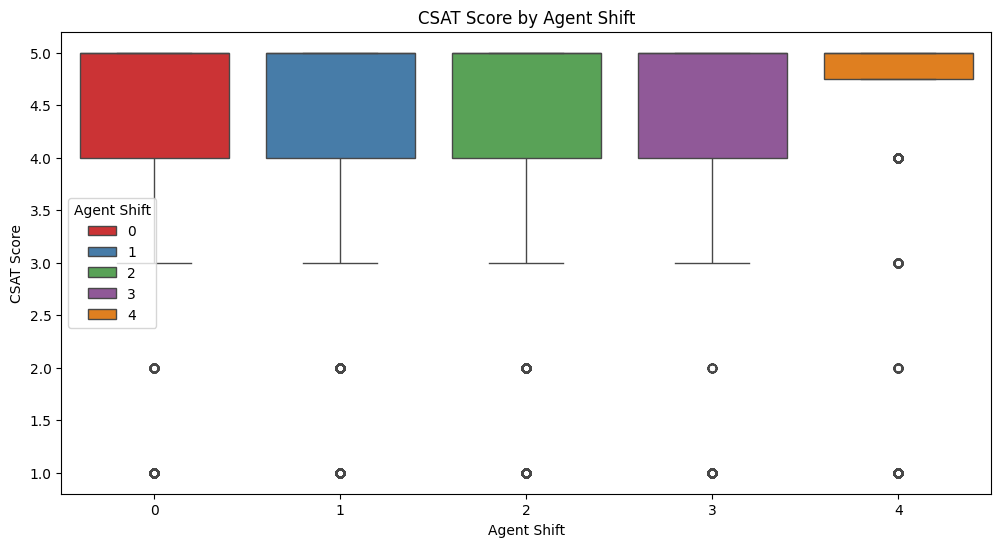

In [27]:
# Handling Outliers & Outlier treatments

# Calculate the IQR for 'CSAT Score'
Q1 = df['CSAT Score'].quantile(0.25)
Q3 = df['CSAT Score'].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers in 'CSAT Score'
outliers = df[(df['CSAT Score'] < lower_bound) | (df['CSAT Score'] > upper_bound)]

print("Number of outliers in 'CSAT Score':", outliers.shape[0])
print(outliers[['Agent Shift', 'CSAT Score']])

# Plot CSAT Score by Agent Shift
plt.figure(figsize=(12, 6))
sns.boxplot(x='Agent Shift', y='CSAT Score', data=df, hue = 'Agent Shift',palette='Set1')
plt.title('CSAT Score by Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('CSAT Score')
plt.show()

##### What all outlier treatment techniques have you used and why did you use those techniques?

Capped outlier values to boundary values to get the data.

In [28]:

# 1# Remove columns that have no effects on testing like ids and timestamps
to_remove = ["UniqueId", "Order_id", "Issue_reported at", "Issue_responded"] 

# 3# Loop through the columns and drop if they exist in the dataframe
df.drop(columns=[col for col in to_remove if col in df.columns], axis=1, inplace=True)

 3.Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [47]:
# Expand Contraction
df.head()

,Unique id,channel_name,category,Sub-category,issue_responded,Survey_response_Date,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,response_time,Issue_reported at (formatted),issue_responded (formatted),Time difference
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,2023-08-01 11:47:00,2023-08-01,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5,2040.0,01/08/23,01/08/23,34.0
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,2023-08-01 12:54:00,2023-08-01,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5,120.0,01/08/23,01/08/23,2.0
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,2023-08-01 20:38:00,2023-08-01,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5,1320.0,01/08/23,01/08/23,22.0
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,2023-08-01 21:16:00,2023-08-01,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5,1200.0,01/08/23,01/08/23,20.0
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,2023-08-01 10:32:00,2023-08-01,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5,120.0,01/08/23,01/08/23,2.0


#### 2. Lower Casing

In [29]:
# Lower Casing



columns_to_clean = ['channel_name', 'category', 'Sub-category', 'Agent_name', 'Supervisor', 'Manager','Tenure Bucket','Agent Shift']

df[columns_to_clean] = df[columns_to_clean].applymap(lambda x: x.lower() if isinstance(x, str) else x)

df[columns_to_clean].head()

C:\Users\91938\AppData\Local\Temp\ipykernel_13092\3394189881.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[columns_to_clean] = df[columns_to_clean].applymap(lambda x: x.lower() if isinstance(x, str) else x)


,channel_name,category,Sub-category,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift
0,2,product queries,life insurance,richard buchanan,mason gupta,jennifer nguyen,on job training,2
1,2,product queries,product specific information,vicki collins,dylan kim,michael lee,>90,2
2,1,order related,installation/demo,duane norman,jackson park,william kim,on job training,1
3,1,returns,reverse pickup enquiry,patrick flores,olivia wang,john smith,>90,1
4,1,cancellation,not needed,christopher sanchez,austin johnson,michael lee,0-30,2


#### 3. Removing Punctuations

In [32]:
import string

for col in columns_to_clean:
    if col in df.columns:
        df[col] = df[col].apply(
            lambda x: x.translate(str.maketrans('', '', string.punctuation))
            if isinstance(x, str) else x
        )

#### 4. Removing URLs & Removing words and digits contain digits.

In [34]:
import pandas as pd

for col in columns_to_clean:
    if col in df.columns:
        # Remove URLs
        df[col] = df[col].apply(
            lambda x: pd.NA if pd.isna(x) else str(x)
        )
        df[col] = df[col].str.replace(
            r'http\S+|www\S+|https\S+',
            '',
            regex=True
        )

        # Remove words containing digits
        df[col] = df[col].str.replace(
            r'\b\w*\d\w*\b',
            '',
            regex=True
        )

print("URLs and words containing digits removed successfully!")

URLs and words containing digits removed successfully!


#### 5. Removing Stopwords & Removing White spaces

In [35]:
# Remove White spaces
for col in columns_to_clean:
    if col in df.columns:
        df[col] = df[col].str.strip()

df.head()

,Unique id,channel_name,category,Sub-category,issue_responded,Survey_response_Date,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,CSAT Score Category,response_time,Issue_reported at (formatted),issue_responded (formatted),Time difference
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,,product queries,life insurance,2023-08-01 11:47:00,2023-08-01,richard buchanan,mason gupta,jennifer nguyen,on job training,,5,1,2040.0,01/08/23,01/08/23,34.0
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,,product queries,product specific information,2023-08-01 12:54:00,2023-08-01,vicki collins,dylan kim,michael lee,,,5,1,120.0,01/08/23,01/08/23,2.0
2,200814dd-27c7-4149-ba2b-bd3af3092880,,order related,installationdemo,2023-08-01 20:38:00,2023-08-01,duane norman,jackson park,william kim,on job training,,5,1,1320.0,01/08/23,01/08/23,22.0
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,,returns,reverse pickup enquiry,2023-08-01 21:16:00,2023-08-01,patrick flores,olivia wang,john smith,,,5,1,1200.0,01/08/23,01/08/23,20.0
4,ba903143-1e54-406c-b969-46c52f92e5df,,cancellation,not needed,2023-08-01 10:32:00,2023-08-01,christopher sanchez,austin johnson,michael lee,,,5,1,120.0,01/08/23,01/08/23,2.0


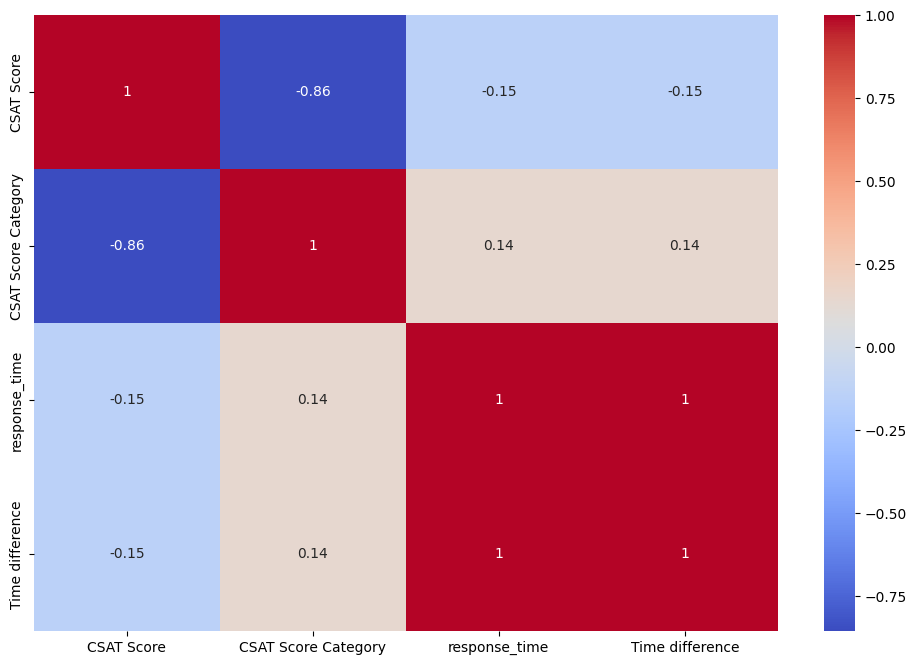

In [36]:
# Compute correlation matrix
# Select only numeric columns from the dataframe
df_numeric = df.select_dtypes(include=['float', 'int'])

# Compute correlation matrix on numeric columns
corr_matrix = df_numeric.corr()

# Visualize the correlation matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

## ***7. ML Model Implementation***

### ML Model - 1

In [37]:
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Create CSAT categories
df["CSAT Score Category"] = pd.cut(
    df["CSAT Score"],
    bins=[1, 2, 3, 4, 5, 6],
    labels=["Very Poor", "Poor", "Average", "Good", "Excellent"],
)

# Encode categorical variables
label_encoder = LabelEncoder()

df["channel_name"] = label_encoder.fit_transform(df["channel_name"])
df["Agent Shift"] = label_encoder.fit_transform(df["Agent Shift"])

df["CSAT Score Category"] = label_encoder.fit_transform(
    df["CSAT Score Category"]
)

# Define features and target
X = df[["Time difference", "Agent Shift"]]
y = df["CSAT Score Category"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# Train Logistic Regression
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(X_train_smote, y_train_smote)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6292049819578629

Classification Report:
              precision    recall  f1-score   support

           0       0.13      0.02      0.04      2244
           1       0.72      0.86      0.78     11924
           2       0.05      0.04      0.05       512
           3       0.02      0.02      0.02       256
           4       0.27      0.23      0.24      2246

    accuracy                           0.63     17182
   macro avg       0.24      0.23      0.23     17182
weighted avg       0.55      0.63      0.58     17182



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [ ]:
# Visualizing evaluation Metric Score chart

#### 2. Cross- Validation & Hyperparameter Tuning

In [38]:
from sklearn.model_selection import cross_val_score, KFold

# Splits the data into k folds
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Implement cross validation
cv_results = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')
print(f'Cross-Validation Accuracy: {cv_results.mean()} ± {cv_results.std()}')

Cross-Validation Accuracy: 0.6279815856239622 ± 0.0051890587587706235


In [40]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score, GridSearchCV

# 1. Implement cross validation
# (Assumes 'model', 'X', 'y', and 'kfold' are already defined upstream)
cv_results = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')
print(f'Cross-Validation Accuracy: {cv_results.mean()} ± {cv_results.std()}')

# 2. Define parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],      # Regularization parameter
    'solver': ['liblinear', 'saga']    # Optimization algorithm
}

# 3. Set up grid search CV
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# 4. Extract and print the best results
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f'Best Parameters: {best_params}')
print(f'Best Score: {best_score}')

Cross-Validation Accuracy: 0.6279815856239622 ± 0.0051890587587706235


C:\Users\91938\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\91938\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\91938\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\91938\AppDat

Best Parameters: {'C': 10, 'solver': 'saga'}
Best Score: 0.48494725354674423


##### Which hyperparameter optimization technique have you used and why?

Hyperparameter tuning is finding the best parameters to your model to improve its performance.GridSerchCV is used as a hyperparameter technique since it works well with classification algorithms.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The accuracy score after using GridSerchCV has went up than the initial test of model.

# **Conclusion**

Machine learning model to create a logistic regression task to predict CSAT Score based on features like time difference and agent shift has been successfully implemented with an accuracy score of 68%.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***